# Task 1: Foundational Setup & Exploratory Data Analysis (EDA)
**Dataset:** Telco Customer Churn (IBM Telco, Kaggle)  
**Goal:** Clean the data, explore it, and find the patterns that explain why customers churn.

**Contents**
1. Setup and data loading
2. Data source and data dictionary
3. Data cleaning and preprocessing
4. Statistical summary
5. Univariate analysis
6. Bivariate analysis
7. Key findings

## 1. Setup and data loading

In [2]:
import warnings
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

warnings.filterwarnings("ignore")
sns.set_theme(style="whitegrid", palette="deep")
plt.rcParams["figure.figsize"] = (8, 5)

ROOT = Path("..")
RAW = ROOT / "data/raw/Telco-Customer-Churn.csv"
PROCESSED = ROOT / "data/processed/telco_churn_clean.csv"
FIGS = ROOT / "reports/figures"
FIGS.mkdir(parents=True, exist_ok=True)

df_raw = pd.read_csv(RAW)
print("Shape:", df_raw.shape)
df_raw.head()

Shape: (7043, 21)


,customerID,gender,SeniorCitizen,Partner,Dependents,tenure,PhoneService,MultipleLines,InternetService,OnlineSecurity,...,DeviceProtection,TechSupport,StreamingTV,StreamingMovies,Contract,PaperlessBilling,PaymentMethod,MonthlyCharges,TotalCharges,Churn
0,7590-VHVEG,Female,0,Yes,No,1,No,No phone service,DSL,No,...,No,No,No,No,Month-to-month,Yes,Electronic check,29.85,29.85,No
1,5575-GNVDE,Male,0,No,No,34,Yes,No,DSL,Yes,...,Yes,No,No,No,One year,No,Mailed check,56.95,1889.5,No
2,3668-QPYBK,Male,0,No,No,2,Yes,No,DSL,Yes,...,No,No,No,No,Month-to-month,Yes,Mailed check,53.85,108.15,Yes
3,7795-CFOCW,Male,0,No,No,45,No,No phone service,DSL,Yes,...,Yes,Yes,No,No,One year,No,Bank transfer (automatic),42.30,1840.75,No
4,9237-HQITU,Female,0,No,No,2,Yes,No,Fiber optic,No,...,No,No,No,No,Month-to-month,Yes,Electronic check,70.70,151.65,Yes


## 2. Data source and understanding
- **Source:** IBM Telco Customer Churn sample dataset, downloaded from Kaggle (*blastchar/telco-customer-churn*).
- **Collection:** Each row is one telecom customer, with account information, subscribed services, billing details and whether the customer left in the last month.
- **Limitations:** single snapshot (no time series), one company, `Churn` is only a one-month label, and no customer satisfaction or competitor data.

| Column | Type | Description |
|---|---|---|
| customerID | text | Unique customer id |
| gender, SeniorCitizen, Partner, Dependents | categorical | Demographics |
| tenure | numeric | Months the customer has stayed |
| PhoneService, MultipleLines, InternetService, OnlineSecurity, TechSupport, StreamingTV ... | categorical | Services subscribed |
| Contract | categorical | Month-to-month / One year / Two year |
| PaperlessBilling, PaymentMethod | categorical | Billing settings |
| MonthlyCharges | numeric | Current monthly bill |
| TotalCharges | numeric | Total billed over the whole tenure |
| Churn | categorical | Yes if the customer left |

In [3]:
df_raw.info()

<class 'pandas.DataFrame'>
RangeIndex: 7043 entries, 0 to 7042
Data columns (total 21 columns):
 #   Column            Non-Null Count  Dtype  
---  ------            --------------  -----  
 0   customerID        7043 non-null   str    
 1   gender            7043 non-null   str    
 2   SeniorCitizen     7043 non-null   int64  
 3   Partner           7043 non-null   str    
 4   Dependents        7043 non-null   str    
 5   tenure            7043 non-null   int64  
 6   PhoneService      7043 non-null   str    
 7   MultipleLines     7043 non-null   str    
 8   InternetService   7043 non-null   str    
 9   OnlineSecurity    7043 non-null   str    
 10  OnlineBackup      7043 non-null   str    
 11  DeviceProtection  7043 non-null   str    
 12  TechSupport       7043 non-null   str    
 13  StreamingTV       7043 non-null   str    
 14  StreamingMovies   7043 non-null   str    
 15  Contract          7043 non-null   str    
 16  PaperlessBilling  7043 non-null   str    
 17  Paymen

In [4]:
print("Missing values per column (raw):")
print(df_raw.isna().sum()[lambda s: s > 0])
print("\nBlank-string TotalCharges:", (df_raw["TotalCharges"].astype(str).str.strip() == "").sum())
print("Duplicate rows:", df_raw.duplicated().sum())

Missing values per column (raw):
Series([], dtype: int64)

Blank-string TotalCharges: 11
Duplicate rows: 0


## 3. Data cleaning and preprocessing

In [5]:
import re
cleaning_log = []
df = df_raw.copy()

def to_snake(name):
    name = re.sub(r"(?<=[a-z0-9])(?=[A-Z])", "_", name.strip())
    return re.sub(r"\W+", "_", name).lower().strip("_")

# 1) standardize column names
df.columns = [to_snake(c) for c in df.columns]
cleaning_log.append("Renamed all columns to snake_case")

# 2) fix data types: TotalCharges is text with blank strings
df["total_charges"] = pd.to_numeric(df["total_charges"], errors="coerce")
cleaning_log.append("Converted total_charges to numeric; blanks became NaN")

# 3) missing values: blanks belong to customers with tenure 0 (nothing billed yet)
mask = df["total_charges"].isna() & (df["tenure"] == 0)
df.loc[mask, "total_charges"] = 0.0
cleaning_log.append(f"Filled {mask.sum()} missing total_charges with 0 (tenure = 0)")
if df["total_charges"].isna().any():
    df["total_charges"] = df["total_charges"].fillna(df["total_charges"].median())
    cleaning_log.append("Filled any remaining total_charges with the median")

# 4) duplicates
n_dup = df.duplicated().sum() + df.duplicated(subset="customer_id").sum()
df = df.drop_duplicates().drop_duplicates(subset="customer_id")
cleaning_log.append(f"Removed {n_dup} duplicate rows")

# 5) data types
df["senior_citizen"] = df["senior_citizen"].map({0: "No", 1: "Yes"})
cat_cols = [c for c in df.columns if c not in ("customer_id", "tenure", "monthly_charges", "total_charges")]
df[cat_cols] = df[cat_cols].astype("category")
df["churn_flag"] = (df["churn"] == "Yes").astype(int)
cleaning_log.append("Converted categorical columns to category dtype; added churn_flag (1/0)")

print("Remaining missing values:", int(df.isna().sum().sum()))
df.dtypes

Remaining missing values: 0


customer_id               str
gender               category
senior_citizen       category
partner              category
dependents           category
tenure                  int64
phone_service        category
multiple_lines       category
internet_service     category
online_security      category
online_backup        category
device_protection    category
tech_support         category
streaming_tv         category
streaming_movies     category
contract             category
paperless_billing    category
payment_method       category
monthly_charges       float64
total_charges         float64
churn                category
churn_flag              int64
dtype: object

### Outlier detection (IQR method)

In [6]:
num_cols = ["tenure", "monthly_charges", "total_charges"]
for col in num_cols:
    q1, q3 = df[col].quantile([0.25, 0.75])
    iqr = q3 - q1
    lo, hi = q1 - 1.5 * iqr, q3 + 1.5 * iqr
    n = int(((df[col] < lo) | (df[col] > hi)).sum())
    msg = f"IQR check on {col}: {n} outliers outside [{lo:.1f}, {hi:.1f}] - kept (valid customers)"
    cleaning_log.append(msg); print(msg)

# z-score cross-check
z = (df[num_cols] - df[num_cols].mean()) / df[num_cols].std()
print("\nRows with |z| > 3 in any numeric column:", int((z.abs() > 3).any(axis=1).sum()))

IQR check on tenure: 0 outliers outside [-60.0, 124.0] - kept (valid customers)
IQR check on monthly_charges: 0 outliers outside [-46.0, 171.4] - kept (valid customers)
IQR check on total_charges: 0 outliers outside [-4683.5, 8868.7] - kept (valid customers)

Rows with |z| > 3 in any numeric column: 0


### Save cleaned data and cleaning log

In [7]:
df.to_csv(PROCESSED, index=False)
cleaning_log.append(f"Saved cleaned data: {df.shape[0]} rows x {df.shape[1]} columns")
(ROOT / "reports/cleaning_log.md").write_text(
    "# Cleaning Log\n\n" + "\n".join(f"{i}. {m}" for i, m in enumerate(cleaning_log, 1)))
for i, m in enumerate(cleaning_log, 1):
    print(i, m)

1 Renamed all columns to snake_case
2 Converted total_charges to numeric; blanks became NaN
3 Filled 11 missing total_charges with 0 (tenure = 0)
4 Removed 0 duplicate rows
5 Converted categorical columns to category dtype; added churn_flag (1/0)
6 IQR check on tenure: 0 outliers outside [-60.0, 124.0] - kept (valid customers)
7 IQR check on monthly_charges: 0 outliers outside [-46.0, 171.4] - kept (valid customers)
8 IQR check on total_charges: 0 outliers outside [-4683.5, 8868.7] - kept (valid customers)
9 Saved cleaned data: 7043 rows x 22 columns


## 4. Statistical summary

In [8]:
df[num_cols + ["churn_flag"]].describe().round(2)

,tenure,monthly_charges,total_charges,churn_flag
count,7043.00,7043.00,7043.00,7043.00
mean,32.37,64.76,2279.73,0.27
std,24.56,30.09,2266.79,0.44
min,0.00,18.25,0.00,0.00
25%,9.00,35.50,398.55,0.00
50%,29.00,70.35,1394.55,0.00
75%,55.00,89.85,3786.60,1.00
max,72.00,118.75,8684.80,1.00


In [9]:
df.describe(include="category").T

,count,unique,top,freq
gender,7043,2,Male,3555
senior_citizen,7043,2,No,5901
partner,7043,2,No,3641
dependents,7043,2,No,4933
phone_service,7043,2,Yes,6361
multiple_lines,7043,3,No,3390
internet_service,7043,3,Fiber optic,3096
online_security,7043,3,No,3498
online_backup,7043,3,No,3088
device_protection,7043,3,No,3095


In [10]:
for col in ["churn", "contract", "internet_service", "payment_method", "senior_citizen"]:
    print(f"--- {col} ---")
    print(df[col].value_counts(normalize=True).mul(100).round(1).astype(str) + " %", "\n")

--- churn ---
churn
No     73.5 %
Yes    26.5 %
Name: proportion, dtype: str 

--- contract ---
contract
Month-to-month    55.0 %
Two year          24.1 %
One year          20.9 %
Name: proportion, dtype: str 

--- internet_service ---
internet_service
Fiber optic    44.0 %
DSL            34.4 %
No             21.7 %
Name: proportion, dtype: str 

--- payment_method ---
payment_method
Electronic check             33.6 %
Mailed check                 22.9 %
Bank transfer (automatic)    21.9 %
Credit card (automatic)      21.6 %
Name: proportion, dtype: str 

--- senior_citizen ---
senior_citizen
No     83.8 %
Yes    16.2 %
Name: proportion, dtype: str 



## 5. Univariate analysis

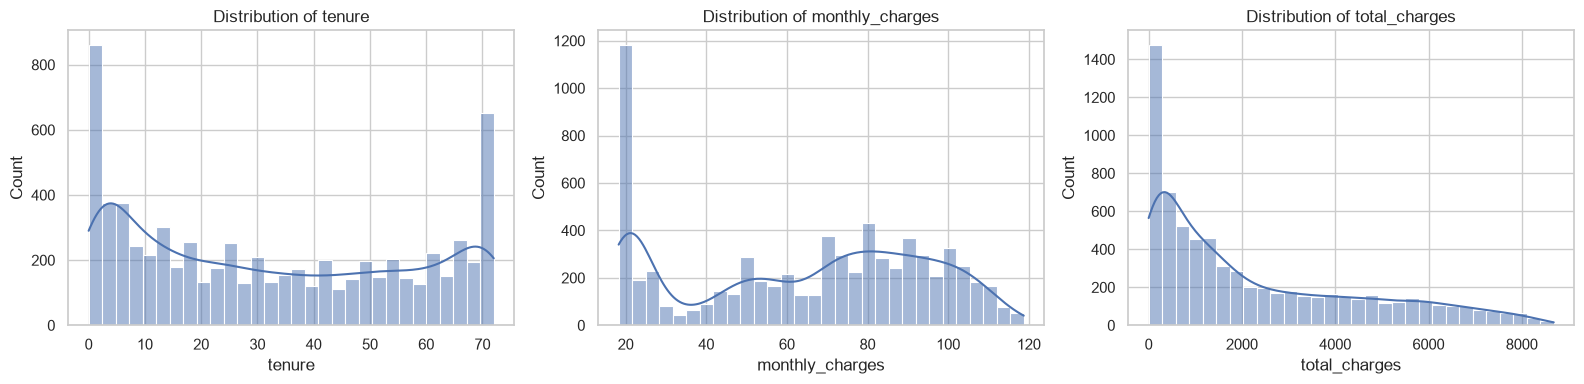

In [11]:
fig, axes = plt.subplots(1, 3, figsize=(16, 4))
for ax, col in zip(axes, num_cols):
    sns.histplot(df[col], bins=30, kde=True, ax=ax)
    ax.set_title(f"Distribution of {col}")
plt.tight_layout()
plt.savefig(FIGS / "01_histograms.png", dpi=150)
plt.show()

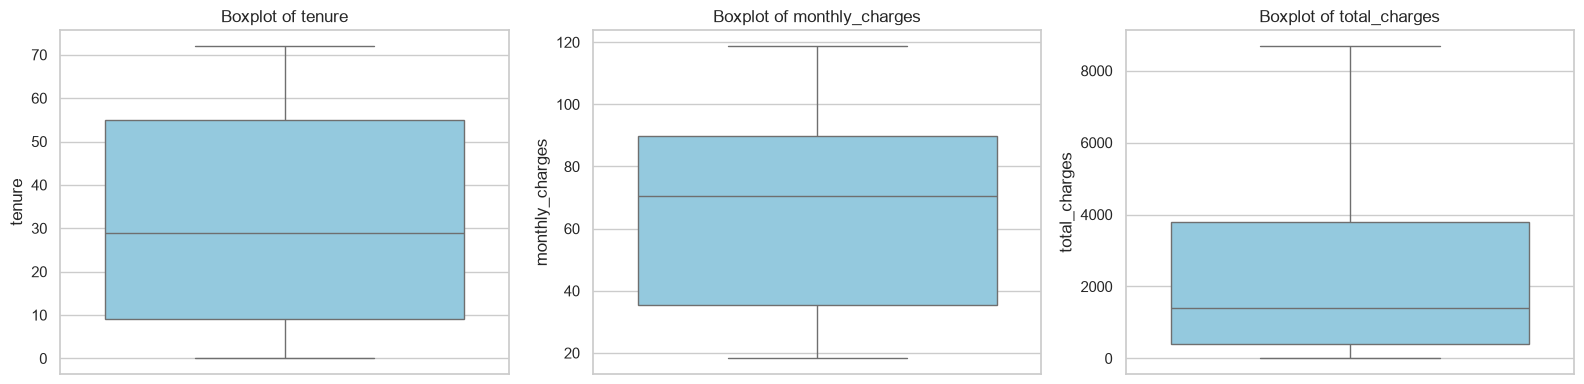

In [12]:
fig, axes = plt.subplots(1, 3, figsize=(16, 4))
for ax, col in zip(axes, num_cols):
    sns.boxplot(y=df[col], ax=ax, color="skyblue")
    ax.set_title(f"Boxplot of {col}")
plt.tight_layout()
plt.savefig(FIGS / "02_boxplots.png", dpi=150)
plt.show()

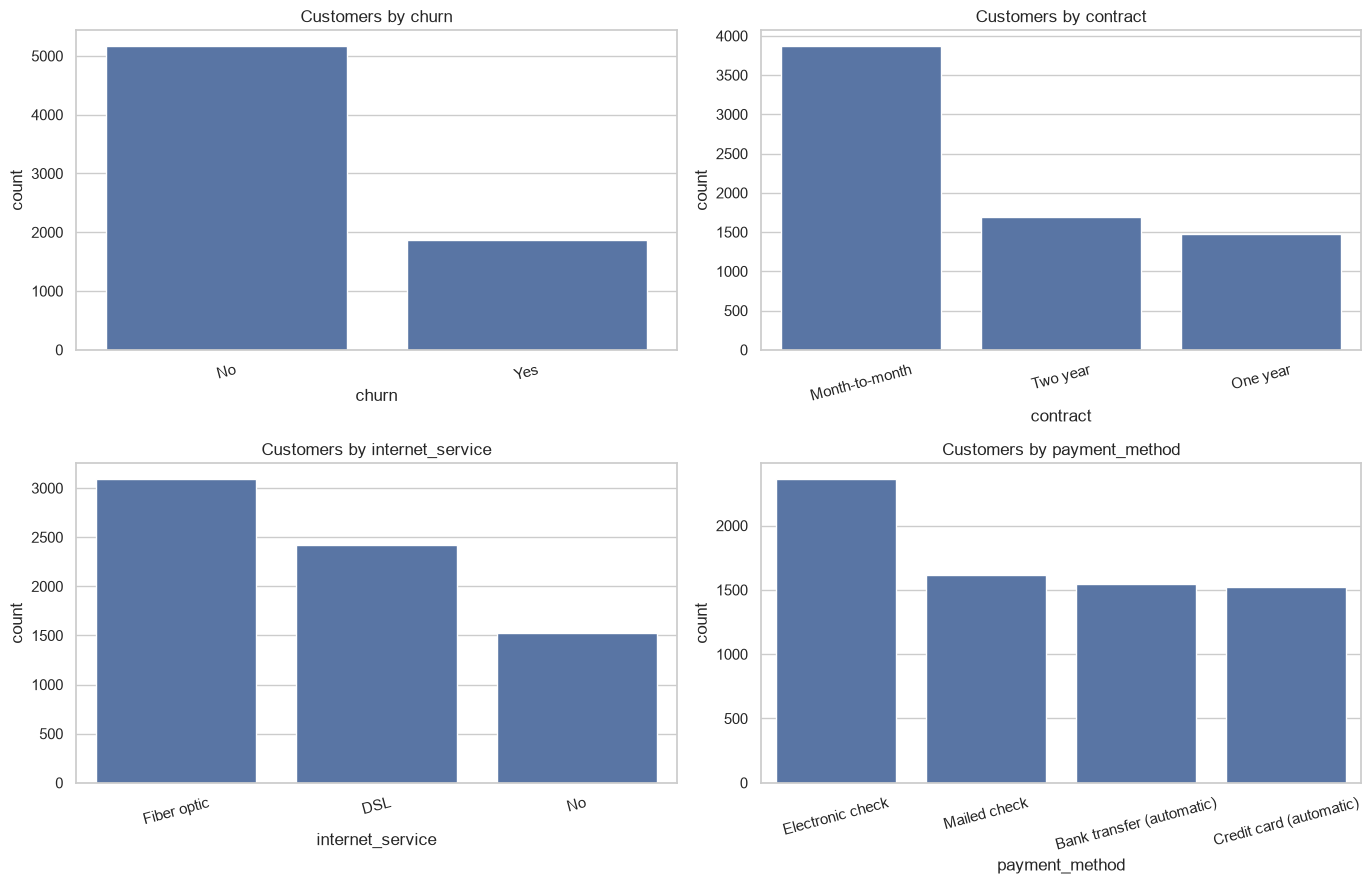

In [13]:
cat_plot = ["churn", "contract", "internet_service", "payment_method"]
fig, axes = plt.subplots(2, 2, figsize=(14, 9))
for ax, col in zip(axes.ravel(), cat_plot):
    order = df[col].value_counts().index
    sns.countplot(data=df, x=col, order=order, ax=ax)
    ax.set_title(f"Customers by {col}")
    ax.tick_params(axis="x", rotation=15)
plt.tight_layout()
plt.savefig(FIGS / "03_bar_charts.png", dpi=150)
plt.show()

## 6. Bivariate analysis

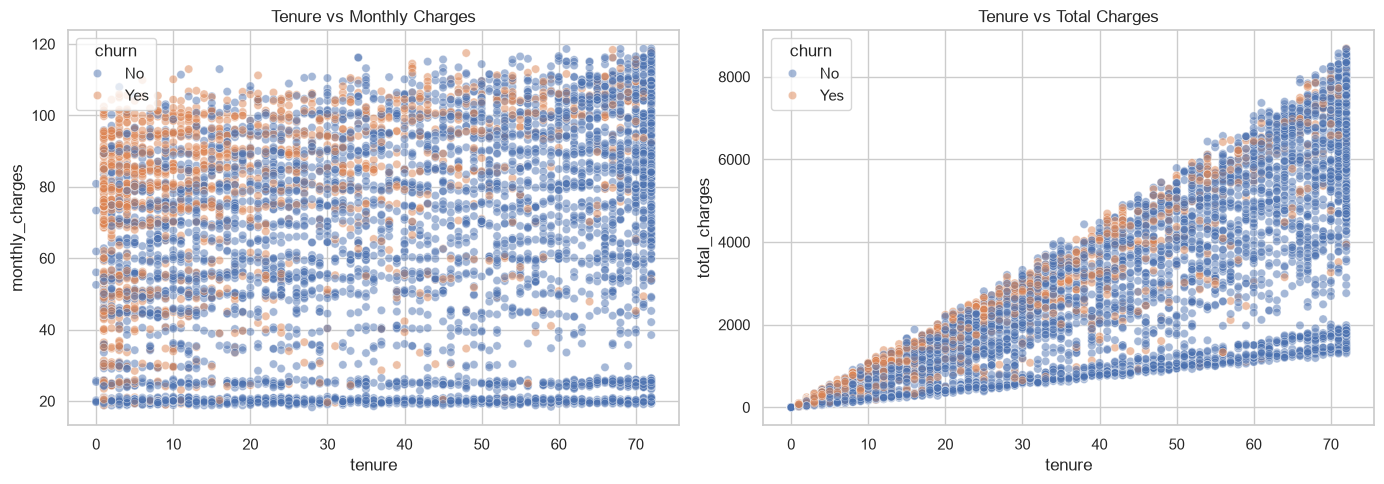

In [14]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5))
sns.scatterplot(data=df, x="tenure", y="monthly_charges", hue="churn", alpha=0.5, ax=axes[0])
axes[0].set_title("Tenure vs Monthly Charges")
sns.scatterplot(data=df, x="tenure", y="total_charges", hue="churn", alpha=0.5, ax=axes[1])
axes[1].set_title("Tenure vs Total Charges")
plt.tight_layout()
plt.savefig(FIGS / "04_scatter.png", dpi=150)
plt.show()

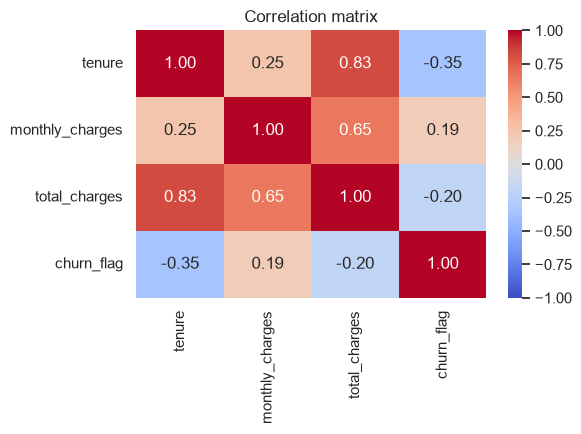

In [15]:
plt.figure(figsize=(6, 4.5))
corr = df[num_cols + ["churn_flag"]].corr()
sns.heatmap(corr, annot=True, cmap="coolwarm", fmt=".2f", vmin=-1, vmax=1)
plt.title("Correlation matrix")
plt.tight_layout()
plt.savefig(FIGS / "05_correlation_heatmap.png", dpi=150)
plt.show()

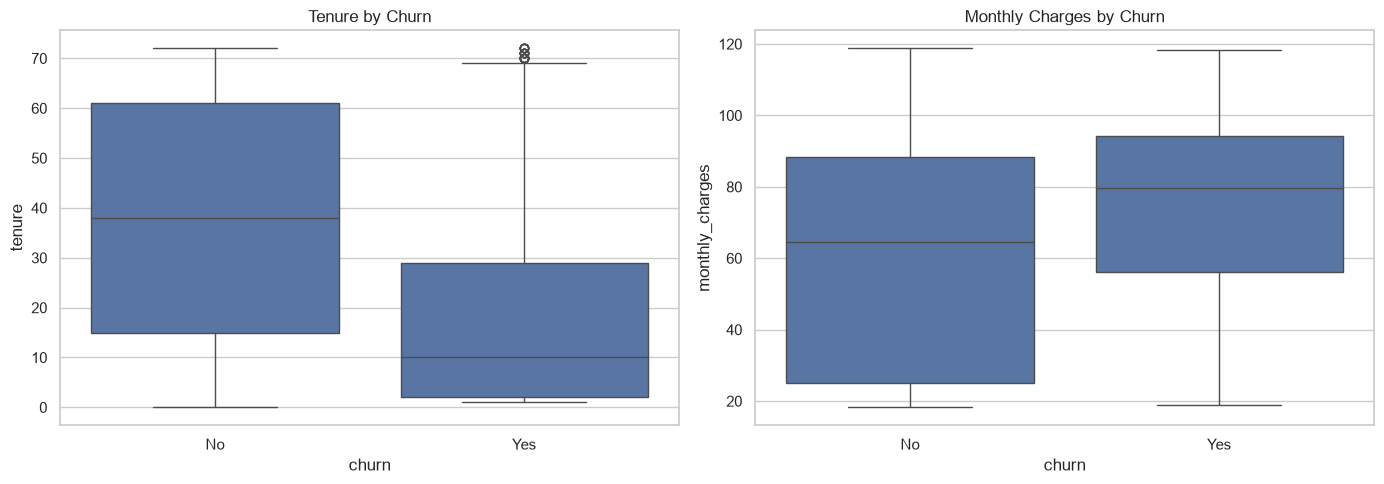

In [16]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5))
sns.boxplot(data=df, x="churn", y="tenure", ax=axes[0])
axes[0].set_title("Tenure by Churn")
sns.boxplot(data=df, x="churn", y="monthly_charges", ax=axes[1])
axes[1].set_title("Monthly Charges by Churn")
plt.tight_layout()
plt.savefig(FIGS / "06_churn_boxplots.png", dpi=150)
plt.show()

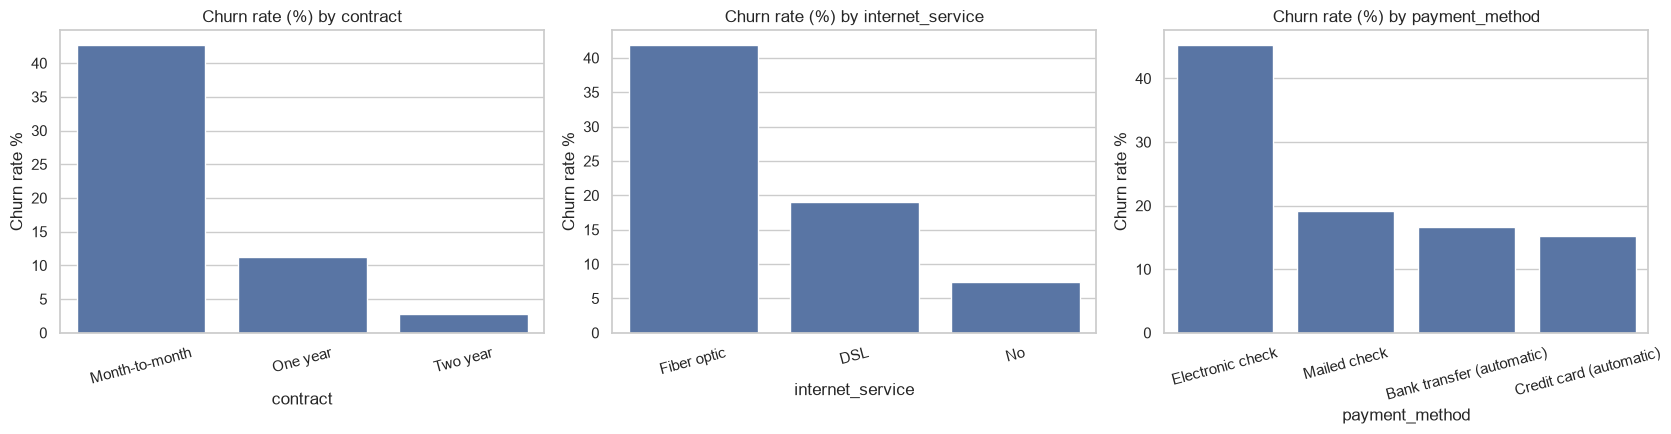

In [17]:
fig, axes = plt.subplots(1, 3, figsize=(17, 4.5))
for ax, col in zip(axes, ["contract", "internet_service", "payment_method"]):
    rate = df.groupby(col, observed=True)["churn_flag"].mean().mul(100).sort_values(ascending=False)
    sns.barplot(x=rate.index.astype(str), y=rate.values, ax=ax)
    ax.set_title(f"Churn rate (%) by {col}")
    ax.set_ylabel("Churn rate %")
    ax.tick_params(axis="x", rotation=15)
plt.tight_layout()
plt.savefig(FIGS / "07_churn_rate_by_category.png", dpi=150)
plt.show()

## 7. Key findings

In [18]:
overall = df["churn_flag"].mean() * 100
by_contract = df.groupby("contract", observed=True)["churn_flag"].mean().mul(100).round(1)
by_internet = df.groupby("internet_service", observed=True)["churn_flag"].mean().mul(100).round(1)
tenure_med = df.groupby("churn", observed=True)["tenure"].median()
mc_med = df.groupby("churn", observed=True)["monthly_charges"].median()

print(f"Overall churn rate: {overall:.1f}%\n")
print("Churn rate by contract (%):\n", by_contract, "\n")
print("Churn rate by internet service (%):\n", by_internet, "\n")
print("Median tenure (months) by churn:\n", tenure_med, "\n")
print("Median monthly charges by churn:\n", mc_med)

Overall churn rate: 26.5%

Churn rate by contract (%):
 contract
Month-to-month    42.7
One year          11.3
Two year           2.8
Name: churn_flag, dtype: float64 

Churn rate by internet service (%):
 internet_service
DSL            19.0
Fiber optic    41.9
No              7.4
Name: churn_flag, dtype: float64 

Median tenure (months) by churn:
 churn
No     38.0
Yes    10.0
Name: tenure, dtype: float64 

Median monthly charges by churn:
 churn
No     64.425
Yes    79.650
Name: monthly_charges, dtype: float64


### Summary of insights
*(Replace the numbers below with the values printed above after running on the real dataset.)*

1. **Contract type is the strongest driver of churn.** Month-to-month customers churn far more than one-year and two-year customers.
2. **New customers leave first.** Churned customers have a much lower median tenure than retained customers, so the first months are the risk window.
3. **Higher monthly charges go with higher churn.** Churned customers pay more per month, and fiber-optic internet users churn more than DSL users.

**Recommendation:** offer incentives to move month-to-month customers to longer contracts, and run onboarding and retention campaigns during the first 6 to 12 months.